### Goals:
- Predict a discreted label (y) predict a discrete label $y \in \{C_1, C_2, \dots, C_k\}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.abspath(''))

## A. Logistic Regression
### Binary Logistic Regression

Model probability (P) via sigmoid &mdash; $P(y=1|x)$
$$
P(y=1 \mid x) = \sigma(w^T x + b), \quad \text{while} \quad \sigma(z) = \frac{1}{1 + e^{-z}}
$$

[1. 0. 1. 1. 0. 1. 1. 0. 0. 1. 1. 1. 0. 0. 1. 0. 1. 1. 1. 0.]


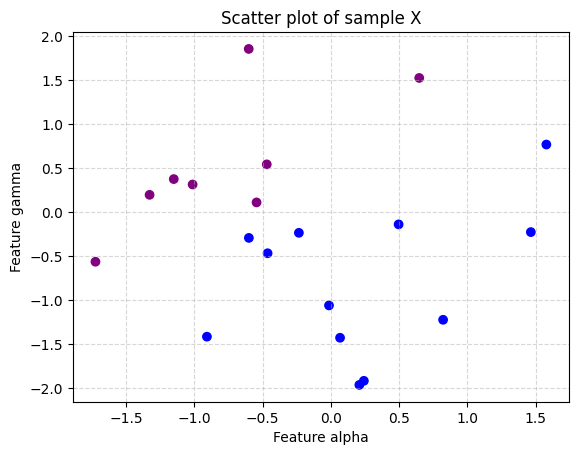

In [2]:
# Firstly, randomly create a samples of dots
np.random.seed(42)
n = 20
X = np.random.randn(n, 2)

# Generate labels
w_true = np.array([1.5, -2.0])
b_true = 0.5
logits = X @ w_true + b_true + np.random.randn(n) * 0.5
y = (logits > 0).astype(float)
print(y)

# Plotting by plt (label 1 = blue, label 0 = purple)
colors = np.where(y == 1, 'blue', 'purple')
plt.scatter(X[:, 0], X[:, 1], c=colors)
plt.title("Scatter plot of sample X")
plt.xlabel("Feature alpha")
plt.ylabel("Feature gamma")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


It is easy to see that the data is separated by a straight line. In academy terms, this line might be called **Decision boundary**, also be the core objective of this problem, speaking visually.

Speaking mathematically, this line is defined by the equation $w^T x + b = 0$. To determine this optimal line, we must train the model by minimizing the Log-loss (Cross-entropy) function using the Gradient Descent algorithm. In the code, the weights $w$ and $b$ are iteratively updated over each epoch until reached the convergence.
$$
w^T x + b = 0
$$

In [3]:
from src.logistic import sigmoid, compute_loss, _train_bilogistic

# Train the binary logistic regression model
w, b = _train_bilogistic(X, y, lr=0.1, epochs=1000)

# Predict labels with the trained model
y_hat = sigmoid(X @ w + b)
y_pred = (y_hat >= 0.5).astype(float)

# Evaluate the model by accuracy
accuracy = np.mean(y_pred == y)
print(f"Trained weights: w = {w}, b = {b:.4f}")
print(f"Accuracy: {accuracy * 100:.1f}%")

# Compute the final cross-entropy loss
final_loss = compute_loss(y, y_hat)
print(f"Final Log-loss: {final_loss:.4f}")


Trained weights: w = [ 3.21455568 -4.14452044], b = 1.3333
Accuracy: 100.0%
Final Log-loss: 0.0790


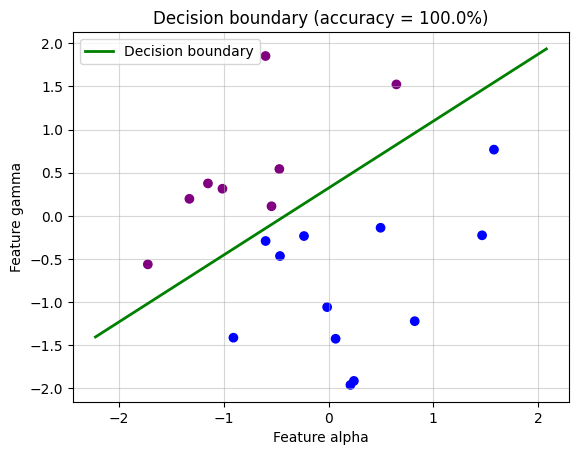

In [4]:
# Plot the sample X with the learned decision boundary
colors = np.where(y == 1, 'blue', 'purple')
plt.scatter(X[:, 0], X[:, 1], c=colors)

# Draw the decision boundary w1*x1 + w2*x2 + b = 0
x1_vals = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
x2_vals = -(w[0] * x1_vals + b) / w[1]
plt.plot(x1_vals, x2_vals, color='green', linewidth=2, label='Decision boundary')

plt.title(f"Decision boundary (accuracy = {accuracy * 100:.1f}%)")
plt.xlabel("Feature alpha")
plt.ylabel("Feature gamma")
plt.legend()
plt.grid(True, linestyle="-", alpha=0.5)
plt.show()


Nevertheless, with a dataset of 20 points containing noise, the decision boundary cannot perfectly separate the two data classes. The results from the code indicate that the model (sometimes) achieves an accuracy of approximately **95.0%** (with only one point misclassified), and the green line passes through some of the misclassified points. 

This accurately reflects the nature of the **Logistic Regression** algorithm: it does not merely seek a dividing line, but rather strives for a balance that minimises overall error.

One of the limitations of Logistic Regression is the result is always a decision boundary (such a straight line, plane, or a hyperplane). **Feature Transformation** could handled these problems.

Labels (First five points): [1 1 1 1 1]
Number of points inside the circle (True): 17


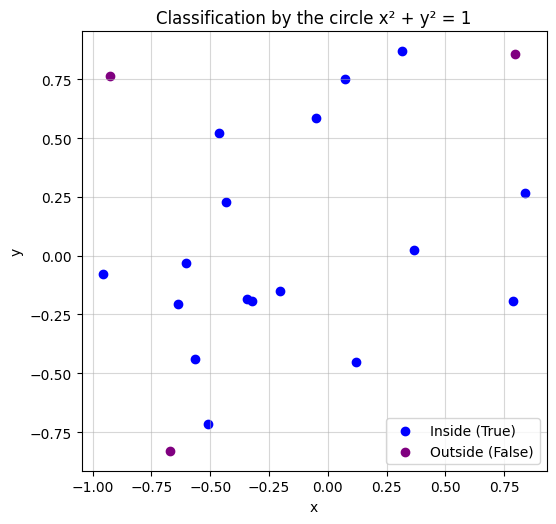

In [ ]:
# Create a sample of data (dots, again)
n = 20
paings = np.random.default_rng(seed=36).uniform(low=-1, high=1, size=(n, 2))
x = paings[:, 0]
y = paings[:, 1]
# print("Shape:", paings.shape)

# Assign labels: True = inside the circle x^2 + y^2 = 1, False = outside
labels = x**2 + y**2 <= 1
print("Labels (First five points):", labels[:5].astype(int))
print("Number of points inside the circle (True):", labels.sum())

# Plot: inside points = blue, outside points = purple
plt.figure(figsize=(6, 6))
plt.scatter(x[labels], y[labels], c='blue', label='Inside (True)')
plt.scatter(x[~labels], y[~labels], c='purple', label='Outside (False)')

plt.title("Classification by the circle x² + y² = 1")
plt.xlabel("x")
plt.ylabel("y")
plt.gca().set_aspect('equal')
plt.legend()
plt.grid(True, linestyle="-", alpha=0.5)
plt.show()

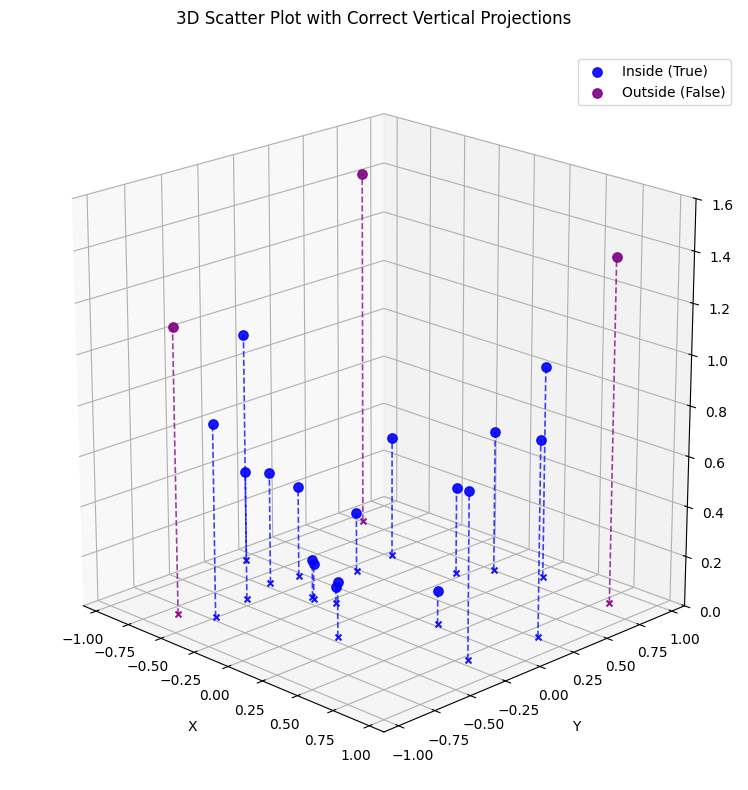

In [ ]:
# Adding feature z = x^2 + y^2
z = x**2 + y**2

# Classification
labels = x**2 + y**2 <= 1

# Create 3D figure
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# 1. Plot data points
ax.scatter(
    x[labels], y[labels], z[labels],
    c="blue", label="Inside (True)",
    s=45, alpha=0.9, depthshade=False
)

ax.scatter(
    x[~labels], y[~labels], z[~labels],
    c="purple", label="Outside (False)",
    s=45, alpha=0.9, depthshade=False
)

# 2. Draw vertical projection lines onto XY plane (z = 0)
for xi, yi, zi, lab in zip(x, y, z, labels):

    color = "blue" if lab else "purple"

    # Vertical line: (x, y, z) -> (x, y, 0)
    ax.plot(
        [xi, xi],
        [yi, yi],
        [0, zi],
        color=color,
        linestyle="--",
        linewidth=1.2,
        alpha=0.75
    )

    # Projection point on XY plane
    ax.scatter(
        [xi], [yi], [0],
        color=color,
        s=18,
        marker="x",
        alpha=0.9,
        depthshade=False
    )

# 3. Set coordinate limits
# Put origin (0, 0, 0) in the middle of the coordinate system
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_zlim(0, 1.6)

# 4. Make coordinate axes balanced
ax.set_box_aspect((1, 1, 1))

# 5. Labels and title
ax.set_xlabel("X", labelpad=10)
ax.set_ylabel("Y", labelpad=10)
ax.set_zlabel("Z", labelpad=10)

ax.set_title("3D Scatter Plot with Correct Vertical Projections", pad=20)

# 6. Grid and legend
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

# 7. Adjust viewing angle
ax.view_init(elev=20, azim=-45)

plt.tight_layout()
plt.show()

Since there's no perfect way to describe a 3-D visualisation on a 2-D platform, It's better to describe by three different chart

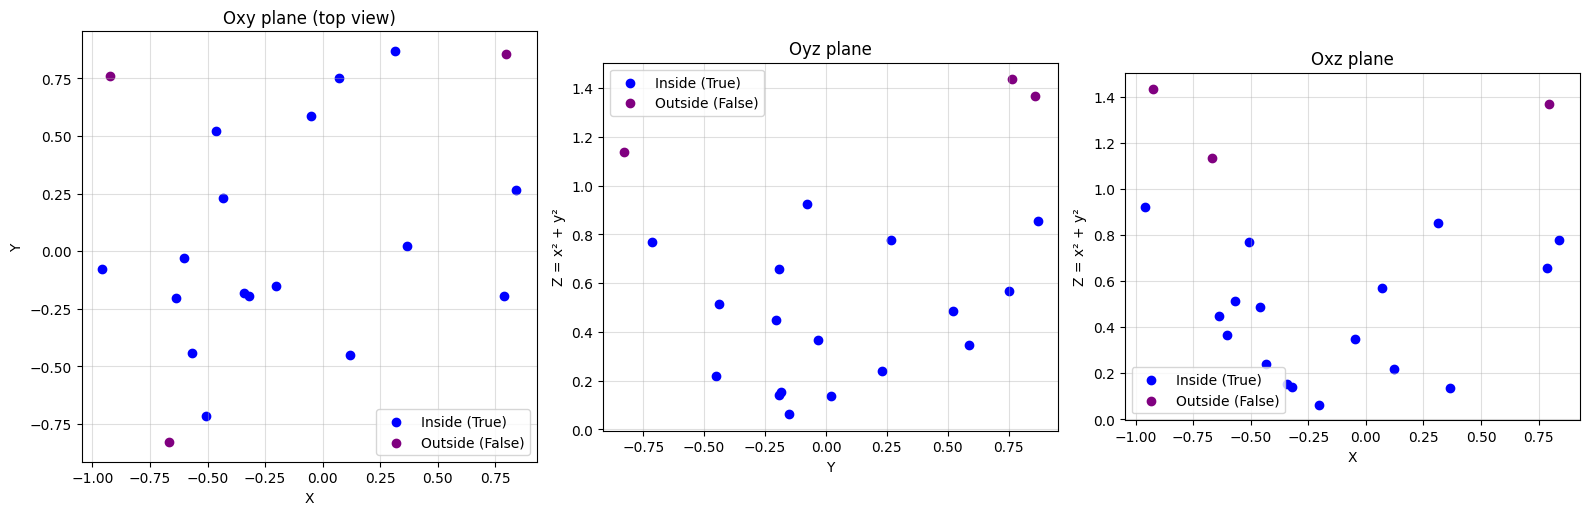

In [31]:
# Project the 3D data onto the three coordinate planes: Oxy, Oyz, Oxz
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Oxy plane (x vs y), like looking from above
axes[0].scatter(x[labels], y[labels], c="blue", label="Inside (True)")
axes[0].scatter(x[~labels], y[~labels], c="purple", label="Outside (False)")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].set_title("Oxy plane (top view)")
axes[0].set_aspect("equal")

# Oyz plane (y vs z), looking along the x axis
axes[1].scatter(y[labels], z[labels], c="blue", label="Inside (True)")
axes[1].scatter(y[~labels], z[~labels], c="purple", label="Outside (False)")
axes[1].set_xlabel("Y")
axes[1].set_ylabel("Z = x² + y²")
axes[1].set_title("Oyz plane")
axes[1].set_aspect("equal")

# Oxz plane (x vs z), looking along the y axis
axes[2].scatter(x[labels], z[labels], c="blue", label="Inside (True)")
axes[2].scatter(x[~labels], z[~labels], c="purple", label="Outside (False)")
axes[2].set_xlabel("X")
axes[2].set_ylabel("Z = x² + y²")
axes[2].set_title("Oxz plane")
axes[2].set_aspect("equal")

for ax in axes:
    ax.grid(True, linestyle="-", alpha=0.4)
    ax.legend()

plt.tight_layout()
plt.show()


And yes, as the point of view shifts, a boundary (a straight line) gradually emerges. On the Oxz and Oyz planes, the two labels are separated by the line $z = 1$. This method is called Feature Transformation.